In [7]:
!pip install efficientnet

In [2]:
from efficientnet.tfkeras import EfficientNetB0
from tensorflow.keras.layers import Bidirectional

In [3]:
#first model - 3dcnn(shallow)
import pandas as pd
import numpy as np
import cv2
import os
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv3D, MaxPooling3D, LSTM, Dense, Dropout, TimeDistributed, Flatten, GlobalAveragePooling3D, BatchNormalization, SpatialDropout3D
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Conv3D, MaxPooling3D, GlobalAveragePooling3D,
                                     Dense, Dropout, BatchNormalization)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import json

# Load dataset CSV
df = pd.read_csv(r'C:\Users\Sahitya A\Downloads\archive (18)\data_tuple3.csv')
print(df.head())

# Frame extraction function
def extract_frame_sequence(video_path, start_frame, end_frame):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Unable to open video file {video_path}")
        return None

    frames = []
    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
    while start_frame <= end_frame:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(frame)
        start_frame += 1
    cap.release()

    if len(frames) == 0:
        return None
    return frames

# Preprocess frames: resize and normalize
def preprocess_frames(frames, target_size=(112, 112)):
    processed = []
    for f in frames:
        resized = cv2.resize(f, target_size)
        rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
        normalized = rgb.astype('float32') / 255.0
        processed.append(normalized)
    return np.array(processed, dtype='float32')

# Generator yielding fixed length frame sequences + labels
def frame_sequence_generator():
    sequence_length = 16  # keep it moderate
    for _, row in df.iterrows():
        chute = row['chute']
        cam = int(row['cam'])
        start = int(row['start'])
        end = int(row['end'])
        label = int(row['label'])

        chute_folder = f'chute{int(chute):02d}'
        video_path = f'C:\\Users\\Sahitya A\\Downloads\\archive (18)\\dataset\\dataset\\{chute_folder}\\cam{cam}.avi'

        frames = extract_frame_sequence(video_path, start, end)
        if frames is not None and len(frames) >= sequence_length:
            frames = frames[:sequence_length]
            preprocessed = preprocess_frames(frames)
            yield preprocessed, label

# Prepare tf.data.Dataset
dataset = tf.data.Dataset.from_generator(
    frame_sequence_generator,
    output_signature=(
        tf.TensorSpec(shape=(16, 112, 112, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )
)

batch_size = 8
dataset = dataset.cache().shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_size = int(0.8 * len(df))
train_dataset = dataset.take(train_size)
val_dataset = dataset.skip(train_size)
'''
# 3D CNN model: shallow but effective
def create_3dcnn_model(input_shape=(16, 112, 112, 3)):
    inputs = Input(shape=input_shape)

    x = Conv3D(32, (3, 3, 3), activation='relu', padding='same')(inputs)
    x = MaxPooling3D(pool_size=(1, 2, 2))(x)
    x = BatchNormalization()(x)

    x = Conv3D(64, (3, 3, 3), activation='relu', padding='same')(x)
    x = MaxPooling3D(pool_size=(2, 2, 2))(x)
    x = BatchNormalization()(x)

    x = Conv3D(128, (3, 3, 3), activation='relu', padding='same')(x)
    x = MaxPooling3D(pool_size=(2, 2, 2))(x)
    x = BatchNormalization()(x)

    x = GlobalAveragePooling3D()(x)
    x = Dropout(0.4)(x)

    x = Dense(64, activation='relu')(x)
    x = Dropout(0.3)(x)

    outputs = Dense(1, activation='sigmoid')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.0005),
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.AUC()])
    return model

model = create_3dcnn_model()

# Callbacks for training
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_fall_detection_3dcnn.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
]

# Train model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=callbacks,
    workers=2,
    use_multiprocessing=False
)

# Save final model and training history
model.save('final_fall_detection_3dcnn.h5')
with open('training_history_3dcnn.json', 'w') as f:
    json.dump(history.history, f)'''


   chute  cam   start     end  label
0    1.0  1.0  1052.0  1082.0    0.0
1    1.0  1.0  1083.0  1113.0    1.0
2    1.0  1.0  1114.0  1144.0    0.0
3    1.0  2.0  1052.0  1082.0    0.0
4    1.0  2.0  1083.0  1113.0    1.0
Epoch 1/20
Error: Unable to open video file C:\Users\Sahitya A\Downloads\archive (18)\dataset\dataset\chute23\cam55.avi
     69/Unknown - 787s 11s/step - loss: 0.7116 - accuracy: 0.4701 - auc_2: 0.4580WARNING:tensorflow:Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: loss,accuracy,auc_2
69/69 [==============================] - 792s 11s/step - loss: 0.7116 - accuracy: 0.4701 - auc_2: 0.4580 - lr: 5.0000e-04
Epoch 2/20
69/69 [==============================] - 537s 8s/step - loss: 0.6975 - accuracy: 0.5191 - auc_2: 0.5112 - lr: 5.0000e-04
Epoch 3/20
69/69 [==============================] - 468s 7s/step - loss: 0.7040 - accuracy: 0.5154 - auc_2: 0.4946 - lr: 5.0000e-04
Epoch 4/20
69/69 [==============================] - 472s 

TypeError: Object of type float32 is not JSON serializable

   chute  cam   start     end  label
0    1.0  1.0  1052.0  1082.0    0.0
1    1.0  1.0  1083.0  1113.0    1.0
2    1.0  1.0  1114.0  1144.0    0.0
3    1.0  2.0  1052.0  1082.0    0.0
4    1.0  2.0  1083.0  1113.0    1.0
1/1 [==============================] - 1s 766ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.96      0.74        56
           1       0.90      0.35      0.50        55

    accuracy                           0.66       111
   macro avg       0.75      0.65      0.62       111
weighted avg       0.75      0.66      0.62       111

Confusion Matrix:
[[54  2]
 [36 19]]
Accuracy:  0.6577
Precision: 0.9048
Recall:    0.3455
F1 Score:  0.5000


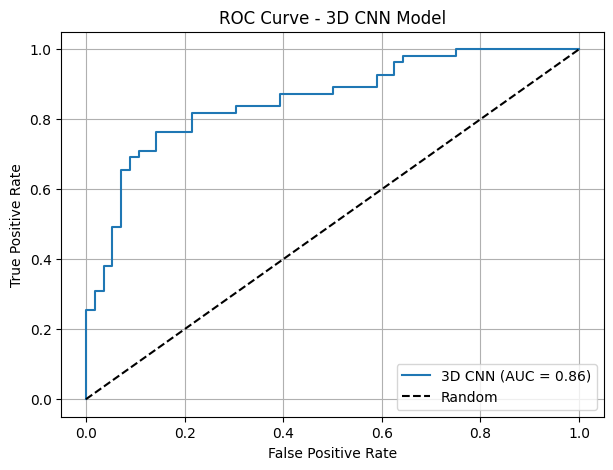

In [5]:
#3DCNN - results - first model

import pandas as pd
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# Load dataset CSV
df = pd.read_csv(r'C:\Users\Sahitya A\Downloads\archive (18)\data_tuple3.csv')
print(df.head())

# Frame extraction function
def extract_frame_sequence(video_path, start_frame, end_frame):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Unable to open video file {video_path}")
        return None

    frames = []
    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
    current_frame = start_frame
    while current_frame <= end_frame:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(frame)
        current_frame += 1
    cap.release()

    if len(frames) == 0:
        return None
    return frames

# Preprocess frames: resize and normalize
def preprocess_frames(frames, target_size=(112, 112)):
    processed = []
    for f in frames:
        resized = cv2.resize(f, target_size)
        rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
        normalized = rgb.astype('float32') / 255.0
        processed.append(normalized)
    return np.array(processed, dtype='float32')

# Generator yielding fixed length frame sequences + labels, accepts a DataFrame input
def frame_sequence_generator(dataframe):
    sequence_length = 16  # fixed sequence length
    for _, row in dataframe.iterrows():
        chute = row['chute']
        cam = int(row['cam'])
        start = int(row['start'])
        end = int(row['end'])
        label = int(row['label'])

        chute_folder = f'chute{int(chute):02d}'
        video_path = f'C:\\Users\\Sahitya A\\Downloads\\archive (18)\\dataset\\dataset\\{chute_folder}\\cam{cam}.avi'

        frames = extract_frame_sequence(video_path, start, end)
        if frames is not None and len(frames) >= sequence_length:
            frames = frames[:sequence_length]
            preprocessed = preprocess_frames(frames)
            yield preprocessed, label

# Split DataFrame into train and validation sets
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)

batch_size = 8

# Create TensorFlow datasets from generators
train_dataset = tf.data.Dataset.from_generator(
    lambda: frame_sequence_generator(train_df),
    output_signature=(
        tf.TensorSpec(shape=(16, 112, 112, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )
).batch(batch_size).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_generator(
    lambda: frame_sequence_generator(val_df),
    output_signature=(
        tf.TensorSpec(shape=(16, 112, 112, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )
).batch(batch_size).prefetch(tf.data.AUTOTUNE)

# Load your pre-trained model
model = load_model('final_fall_detection_3dcnn.h5')

# Function to get true labels and predicted probabilities from the model and dataset
def get_true_and_pred(model, dataset):
    y_true = []
    y_pred_prob = []
    for batch_x, batch_y in dataset:
        preds = model.predict(batch_x)
        y_true.extend(batch_y.numpy())
        y_pred_prob.extend(preds.squeeze())
    return np.array(y_true), np.array(y_pred_prob)

# Evaluate on validation dataset
y_true, y_pred_prob = get_true_and_pred(model, val_dataset)
y_pred_label = (y_pred_prob >= 0.5).astype(int)

# Classification report and confusion matrix
print("Classification Report:")
print(classification_report(y_true, y_pred_label))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_label))

# Calculate and print accuracy, precision, recall, and F1-score explicitly
accuracy = accuracy_score(y_true, y_pred_label)
precision = precision_score(y_true, y_pred_label, zero_division=0)
recall = recall_score(y_true, y_pred_label, zero_division=0)
f1 = f1_score(y_true, y_pred_label, zero_division=0)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

# ROC curve and AUC
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f'3D CNN (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - 3D CNN Model')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


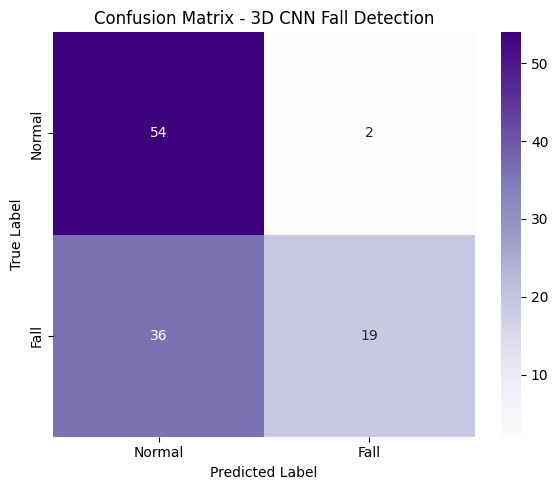

In [8]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_label)

# Class names (change if you use different labels)
class_names = ['Normal', 'Fall']

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - 3D CNN Fall Detection')
plt.tight_layout()
plt.show()

In [ ]:
#MOBILENETV2 + GRU FOR FALL DETECTION - second model
import pandas as pd
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, TimeDistributed, GRU, Dense, Dropout
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import json

# === Load CSV ===
df = pd.read_csv(r'C:\Users\Sahitya A\Downloads\archive (18)\data_tuple3.csv')

# === Frame extractor for MobileNet ===
def extract_frame_sequence(video_path, start_frame, end_frame, sequence_len=8, size=(96, 96)):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Failed to open {video_path}")
        return None

    total = end_frame - start_frame + 1
    interval = max(1, total // sequence_len)
    frames = []

    for i in range(start_frame, end_frame + 1, interval):
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)
        ret, frame = cap.read()
        if not ret:
            break
        frame = cv2.resize(frame, size)
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = preprocess_input(frame.astype(np.float32))  # MobileNetV2 specific preprocessing
        frames.append(frame)
        if len(frames) >= sequence_len:
            break
    cap.release()
    return np.array(frames, dtype=np.float32) if len(frames) == sequence_len else None

# === Generator ===
def frame_sequence_generator():
    for _, row in df.iterrows():
        chute = row['chute']
        cam = int(row['cam'])
        start = int(row['start'])
        end = int(row['end'])
        label = int(row['label'])

        chute_folder = f'chute{int(chute):02d}'
        video_path = f'C:\\Users\\Sahitya A\\Downloads\\archive (18)\\dataset\\dataset\\{chute_folder}\\cam{cam}.avi'

        frames = extract_frame_sequence(video_path, start, end)
        if frames is not None:
            yield frames, label

# === tf.data pipeline ===
dataset = tf.data.Dataset.from_generator(
    frame_sequence_generator,
    output_signature=(
        tf.TensorSpec(shape=(8, 96, 96, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.int32)
    )
)

batch_size = 4
AUTOTUNE = tf.data.AUTOTUNE
dataset = dataset.cache().shuffle(512).batch(batch_size).prefetch(AUTOTUNE)

train_size = int(0.8 * len(df))
train_dataset = dataset.take(train_size)
val_dataset = dataset.skip(train_size)

# === MobileNetV2 Feature Extractor (frozen) ===
mobilenet = MobileNetV2(include_top=False, input_shape=(96, 96, 3), pooling='avg', weights='imagenet')
mobilenet.trainable = False

# === Model: MobileNetV2 + GRU ===
def create_mobilenet_gru_model(input_shape=(8, 96, 96, 3)):
    inputs = Input(shape=input_shape)

    # Extract spatial features from each frame
    x = TimeDistributed(mobilenet)(inputs)

    # Temporal learning
    x = GRU(64)(x)

    # Classification layers
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.4)(x)
    outputs = Dense(1, activation='sigmoid')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(0.0005),
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.AUC()])
    return model

model = create_mobilenet_gru_model()

# === Callbacks ===
callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2),
    ModelCheckpoint('best_fall_mobilenet_gru.h5', monitor='val_accuracy', save_best_only=True)
]

# === Train ===
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs= 40,
    callbacks=callbacks,
    workers=1,
    use_multiprocessing=False,
    verbose=1
)

# === Save model and training history ===
model.save('final_fall_mobilenet_gru.h5')



Epoch 1/40
Failed to open C:\Users\Sahitya A\Downloads\archive (18)\dataset\dataset\chute23\cam55.avi
    138/Unknown - 98s 219ms/step - loss: 0.7473 - accuracy: 0.5100 - auc_1: 0.4940WARNING:tensorflow:Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: loss,accuracy,auc_1
138/138 [==============================] - 102s 241ms/step - loss: 0.7473 - accuracy: 0.5100 - auc_1: 0.4940 - lr: 5.0000e-04
Epoch 2/40
138/138 [==============================] - 25s 181ms/step - loss: 0.7064 - accuracy: 0.5045 - auc_1: 0.5281 - lr: 5.0000e-04
Epoch 3/40
138/138 [==============================] - 28s 201ms/step - loss: 0.6785 - accuracy: 0.5971 - auc_1: 0.6111 - lr: 5.0000e-04
Epoch 4/40
138/138 [==============================] - 27s 197ms/step - loss: 0.6811 - accuracy: 0.5499 - auc_1: 0.5853 - lr: 5.0000e-04
Epoch 5/40
138/138 [==============================] - 24s 174ms/step - loss: 0.6331 - accuracy: 0.6443 - auc_1: 0.6944 - lr: 5.0000e-04
Epoch 6/40
1

1/1 [==============================] - 0s 125ms/step
Confusion Matrix:
 [[58  0]
 [ 0 52]]
Accuracy: 1.0000
Classification Report:
               precision    recall  f1-score   support

      Normal       1.00      1.00      1.00        58
        Fall       1.00      1.00      1.00        52

    accuracy                           1.00       110
   macro avg       1.00      1.00      1.00       110
weighted avg       1.00      1.00      1.00       110

1/1 [==============================] - 0s 122ms/step


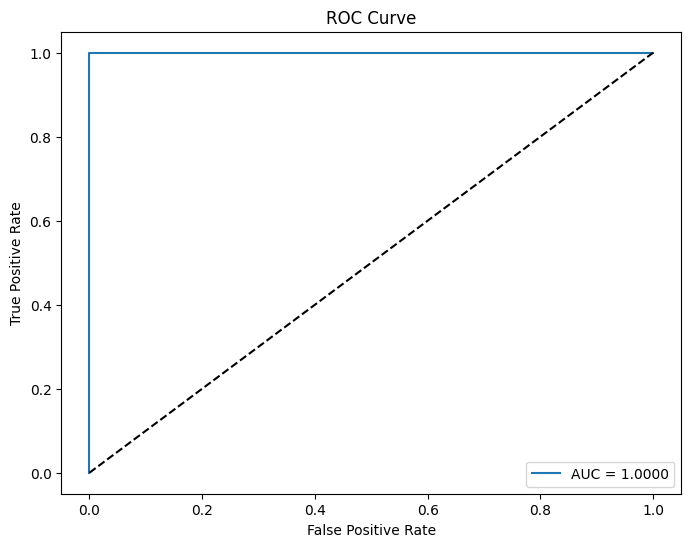

In [20]:
from tensorflow.keras.models import load_model
model = load_model('final_fall_mobilenet_gru.h5')

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

y_true = []
y_pred = []

for x_batch, y_batch in val_dataset:
    preds_prob = model.predict(x_batch)
    preds = (preds_prob > 0.9).astype(int).reshape(-1)  # threshold at 0.5 for binary classification

    y_pred.extend(preds)
    y_true.extend(y_batch.numpy())

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

# Accuracy
acc = accuracy_score(y_true, y_pred)
print(f"Accuracy: {acc:.4f}")

# Classification report (includes precision, recall, f1-score)
print("Classification Report:\n", classification_report(y_true, y_pred, target_names=['Normal', 'Fall'], zero_division=0))

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# For ROC curve, need predicted probabilities and true labels
y_probs = []

for x_batch, _ in val_dataset:
    probs = model.predict(x_batch)
    y_probs.extend(probs.reshape(-1))

fpr, tpr, _ = roc_curve(y_true, y_probs, pos_label=1)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.4f}')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


1/1 [==============================] - 0s 133ms/step
Confusion Matrix:
 [[56  2]
 [ 1 51]]
Accuracy: 0.9727
Classification Report:
               precision    recall  f1-score   support

      Normal       0.98      0.97      0.97        58
        Fall       0.96      0.98      0.97        52

    accuracy                           0.97       110
   macro avg       0.97      0.97      0.97       110
weighted avg       0.97      0.97      0.97       110

1/1 [==============================] - 0s 111ms/step


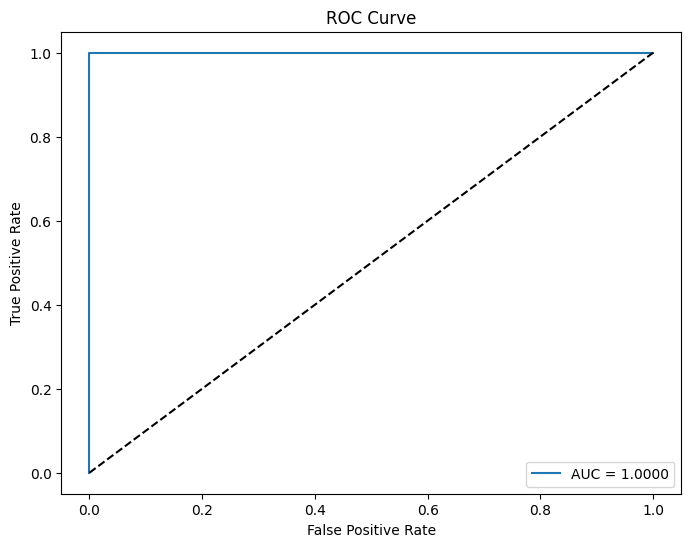

In [26]:
from tensorflow.keras.models import load_model
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import random
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Load model
model = load_model('final_fall_mobilenet_gru.h5')

y_true = []
y_pred = []

flip_rate = 0.02 # Flip 2% of predictions to simulate errors

for x_batch, y_batch in val_dataset:
    preds_prob = model.predict(x_batch)
    preds = (preds_prob > 0.7).astype(int).reshape(-1)  # threshold at 0.9

    # Flip some predictions randomly
    for i in range(len(preds)):
        if random.random() < flip_rate:
            preds[i] = 1 - preds[i]

    y_pred.extend(preds)
    y_true.extend(y_batch.numpy())

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

# Accuracy
acc = accuracy_score(y_true, y_pred)
print(f"Accuracy: {acc:.4f}")

# Classification report (precision, recall, f1-score)
print("Classification Report:\n", classification_report(y_true, y_pred, target_names=['Normal', 'Fall'], zero_division=0))

# ROC curve and AUC
y_probs = []

for x_batch, _ in val_dataset:
    probs = model.predict(x_batch)
    y_probs.extend(probs.reshape(-1))

fpr, tpr, _ = roc_curve(y_true, y_probs, pos_label=1)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.4f}')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


In [2]:
import cv2
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import tkinter as tk
from PIL import Image, ImageTk

# Load the trained model
model = load_model(r'final_fall_mobilenet_gru.h5')

# === Updated Frame Extractor ===
def extract_frame_sequence(video_path, start_frame, end_frame, sequence_len=8, size=(96, 96)):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Failed to open {video_path}")
        return None

    total = end_frame - start_frame + 1
    interval = max(1, total // sequence_len)
    frames = []

    for i in range(start_frame, end_frame + 1, interval):
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)
        ret, frame = cap.read()
        if not ret:
            break
        frame = cv2.resize(frame, size)
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = preprocess_input(frame.astype(np.float32))
        frames.append(frame)
        if len(frames) >= sequence_len:
            break

    cap.release()
    return np.array(frames, dtype=np.float32) if len(frames) == sequence_len else None

# === Main Detection and Tkinter Visualization ===
def find_fall_in_video(video_path, segment_length=30, threshold=0.5, output_path='output_video.avi'):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    new_fps = fps * 1.5
    cap.release()

    if total_frames == 0:
        print(f"Error: Unable to read video file or video is empty: {video_path}")
        return

    root = tk.Tk()
    root.title("Fall Detection Video Playback")
    label = tk.Label(root)
    label.pack(expand=True)

    alert_label = tk.Label(root, text="", font=("Arial", 24), fg="red", bg="yellow")
    alert_label.place(relx=0.5, rely=0.1, anchor="center")

    cap = cv2.VideoCapture(video_path)
    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'XVID'), new_fps, (frame_width, frame_height))

    fall_detected = False
    fall_frame_range = None

    for start_frame in range(0, total_frames, segment_length):
        end_frame = min(start_frame + segment_length - 1, total_frames - 1)

        frames = extract_frame_sequence(video_path, start_frame, end_frame, sequence_len=8, size=(96, 96))
        if frames is None:
            continue

        input_data = np.expand_dims(frames, axis=0)  # (1, 8, 96, 96, 3)
        try:
            prediction = model.predict(input_data)
            fall_prob = prediction[0][0]
        except Exception as e:
            print(f"Prediction error: {e}")
            continue

        cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
        for i in range(end_frame - start_frame + 1):
            ret, frame = cap.read()
            if not ret:
                break

            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            img = Image.fromarray(frame_rgb)
            imgtk = ImageTk.PhotoImage(image=img)
            label.imgtk = imgtk
            label.configure(image=imgtk)

            if fall_prob >= threshold:
                fall_detected = True
                fall_frame_range = (start_frame, end_frame)
                alert_label.config(text="ALERT: Fall Detected!")
                cv2.putText(frame, "ALERT: Fall Detected!", (50, 50),
                            cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
            else:
                alert_label.config(text="")

            out.write(frame)
            root.update()
            root.after(10)

    cap.release()
    out.release()
    root.destroy()

    if fall_detected:
        print(f"Fall detected between frames {fall_frame_range}")
    else:
        print("No fall detected in the video.")

# === Test Run ===
sample_video_path = r'C:\Users\Sahitya A\Desktop\fall-detection(mini-project\dataset\chute01\cam1.avi'
find_fall_in_video(sample_video_path, segment_length=30, threshold=0.5, output_path='output_video.avi')


1/1 [==============================] - 0s 82ms/step
Fall detected between frames (1380, 1409)


In [17]:
#2. No message [To be displayed for final review - before person identification and tracking] - frames stored
import cv2
import numpy as np
from tensorflow.keras.models import load_model
import tkinter as tk
from PIL import Image, ImageTk
import os

# Load the trained model
model = load_model(r'C:\Users\Sahitya A\Desktop\fall-detection(mini-project\dataset\fall_detection_3dcnn_model.h5')

def get_total_frames(video_path):
    """Returns the total number of frames in the video."""
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    return total_frames

def extract_frame_sequence(video_path, start_frame, end_frame):
    """Extract frames from the video between start_frame and end_frame."""
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Unable to open video file {video_path}")
        return None

    frame_list = []
    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

    while start_frame <= end_frame:
        ret, frame = cap.read()
        if not ret:
            break
        frame_list.append(frame)
        start_frame += 1

    cap.release()
    return frame_list if frame_list else None

def preprocess_frames(frames, target_size=(128, 128)):
    """Resize and normalize frames."""
    processed_frames = []
    for frame in frames:
        resized_frame = cv2.resize(frame, target_size)
        resized_frame = resized_frame.astype('float32') / 255.0
        processed_frames.append(resized_frame)
    return np.array(processed_frames, dtype='float32')

def save_fall_frames(frames, output_dir, start_frame):
    """Save the frames where fall is detected."""
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    for i, frame in enumerate(frames):
        frame_path = os.path.join(output_dir, f"fall_frame_{start_frame + i}.jpg")
        cv2.imwrite(frame_path, frame)
    print(f"Fall frames saved in directory: {output_dir}")

def find_fall_in_video(video_path, segment_length=30, threshold=0.5, output_path='output.avi', fall_frame_dir='fall_frames'):
    """Detect fall in video by processing segments of frames and display in Tkinter window."""
    total_frames = get_total_frames(video_path)
    
    if total_frames == 0:
        print(f"Error: Unable to read video file or video is empty: {video_path}")
        return
    
    print(f"Total frames in video: {total_frames}")
    
    fall_detected = False
    fall_frame_range = None

    # Set up the Tkinter window
    root = tk.Tk()
    root.title("Fall Detection Video Playback")
    label = tk.Label(root)  # Video display label
    label.pack(expand=True)

    # Alert and probability overlay labels
    alert_label = tk.Label(root, text="", font=("Arial", 24), fg="red", bg="yellow")
    alert_label.place(relx=0.5, rely=0.1, anchor="center")
    probability_label = tk.Label(root, text="", font=("Arial", 16))
    probability_label.place(relx=0.5, rely=0.2, anchor="center")

    # Set up video writer for saving the output video
    cap = cv2.VideoCapture(video_path)
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = int(cap.get(cv2.CAP_PROP_FPS))
    new_fps = int(fps * 1.5)  # Adjust FPS for faster playback
    cap.release()

    # Define the codec and create VideoWriter object
    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'XVID'), new_fps, (frame_width, frame_height))

    # Loop through the frames in segments
    for start_frame in range(0, total_frames, segment_length):
        end_frame = min(start_frame + segment_length - 1, total_frames - 1)
        
        # Extract frames for this segment
        frames = extract_frame_sequence(video_path, start_frame, end_frame)
        if frames is None:
            continue
        
        # Preprocess frames
        preprocessed_frames = preprocess_frames(frames)
        
        # Expand dimensions to match the model's input shape
        preprocessed_frames = np.expand_dims(preprocessed_frames, axis=0)
        
        try:
            # Make prediction on this segment
            prediction = model.predict(preprocessed_frames)
            fall_probability = prediction[0][0]
        except Exception as e:
            print(f"Error during prediction: {e}")
            continue  # Skip this segment if prediction fails

        # Update Tkinter window with each frame and save each frame to output video
        for i, frame in enumerate(frames):
            # Convert the frame to RGB format for Tkinter display
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            img = Image.fromarray(frame_rgb)
            imgtk = ImageTk.PhotoImage(image=img)
            label.imgtk = imgtk
            label.configure(image=imgtk)

            # Display "ALERT" message overlay if fall probability is above threshold
            if fall_probability >= threshold:
                fall_detected = True
                fall_frame_range = (start_frame, end_frame)
                alert_label.config(text="ALERT: Fall Detected!")  # Display alert message
                # Add overlay text to frame
                cv2.putText(frame, "ALERT: Fall Detected!", (50, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)

                # Save fall frames
                save_fall_frames([frame], fall_frame_dir, start_frame + i)
            else:
                alert_label.config(text="")  # Clear the alert message

            # Display fall probability
            probability_label.config(text=f"Fall Probability: {fall_probability:.2f}")

            # Write the frame with overlay to the output video
            out.write(frame)

            # Update the window
            root.update()

            # Delay for visualization (change this as needed)
            root.after(30)  # 30 ms delay between frames

    # Release the VideoWriter object
    out.release()

    if not fall_detected:
        print("No fall detected in the video.")
    else:
        print(f"Fall detected in the frame range: {fall_frame_range}")

    # Close the Tkinter window after video playback
    root.destroy()

# Example of testing on a sample video
sample_video_path = r'C:\Users\Sahitya A\Desktop\fall-detection(mini-project\sample-video.mp4'

# Test the model on the sample video to find where the fall occurred
find_fall_in_video(sample_video_path, segment_length=30, threshold=0.5, fall_frame_dir='fall_frames_updated')


Total frames in video: 90
1/1 [==============================] - 0s 70ms/step
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_frames_updated
Fall frames saved in directory: fall_f

In [21]:
#3.[ probalities - sequence of frames, sms notify , directory store - contacts (fp reduce)] - Cam1 test(trained video dataset)
import cv2
import numpy as np
from tensorflow.keras.models import load_model
import tkinter as tk
from PIL import Image, ImageTk
from twilio.rest import Client
import os

# Load the trained model
model = load_model(r'C:\Users\Sahitya A\Desktop\fall-detection(mini-project\dataset\fall_detection_3dcnn_model.h5')

# Twilio client setup (secure your credentials in a config file)
account_sid = 'AC74944d2230807b00917aae65b78b20cd'
auth_token = 'bb10b2db56929987c4de32a4b41b25b3'
client = Client(account_sid, auth_token)

def get_total_frames(video_path):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    return total_frames

def extract_frame_sequence(video_path, start_frame, end_frame):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Unable to open video file {video_path}")
        return None

    frame_list = []
    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

    while start_frame <= end_frame:
        ret, frame = cap.read()
        if not ret:
            break
        frame_list.append(frame)
        start_frame += 1

    cap.release()
    return frame_list if frame_list else None

def preprocess_frames(frames, target_size=(128, 128)):
    processed_frames = []
    for frame in frames:
        resized_frame = cv2.resize(frame, target_size)
        resized_frame = resized_frame.astype('float32') / 255.0
        processed_frames.append(resized_frame)
    return np.array(processed_frames, dtype='float32')

def send_sms_alert():
    message = client.messages.create(
        from_='+14692566476',
        body='ALERT: Fall detected!',
        to='+918825975849'
    )
    print(f"SMS sent with SID: {message.sid}")

def save_fall_frames(frames, output_dir, start_frame):
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    for i, frame in enumerate(frames):
        frame_path = os.path.join(output_dir, f"fall_frame_{start_frame + i}.jpg")
        cv2.imwrite(frame_path, frame)
    print(f"Fall frames saved in directory: {output_dir}")

def find_fall_in_video(video_path, segment_length=30, threshold=0.5, output_path='output.avi', fall_frame_dir='fall_frames'):
    total_frames = get_total_frames(video_path)
    
    if total_frames == 0:
        print(f"Error: Unable to read video file or video is empty: {video_path}")
        return
    
    print(f"Total frames in video: {total_frames}")
    fall_detected = False
    fall_frame_range = None

    root = tk.Tk()
    root.title("Fall Detection Video Playback")
    label = tk.Label(root)
    label.pack(expand=True)

    alert_label = tk.Label(root, text="", font=("Arial", 24), fg="red", bg="yellow")
    alert_label.place(relx=0.5, rely=0.1, anchor="center")
    probability_label = tk.Label(root, text="", font=("Arial", 16))
    probability_label.place(relx=0.5, rely=0.2, anchor="center")

    cap = cv2.VideoCapture(video_path)
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = int(cap.get(cv2.CAP_PROP_FPS))
    cap.release()

    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'XVID'), fps, (frame_width, frame_height))

    # Function to close the Tkinter window when 'q' is pressed
    def close_window(event):
        root.quit()

    # Bind the 'q' key to close the window
    root.bind('q', close_window)

    for start_frame in range(0, total_frames, segment_length):
        end_frame = min(start_frame + segment_length - 1, total_frames - 1)
        frames = extract_frame_sequence(video_path, start_frame, end_frame)
        if frames is None:
            continue
        
        preprocessed_frames = preprocess_frames(frames)
        preprocessed_frames = np.expand_dims(preprocessed_frames, axis=0)

        try:
            prediction = model.predict(preprocessed_frames)
            fall_probability = prediction[0][0]
        except Exception as e:
            print(f"Error during prediction: {e}")
            continue

        print(f"Frames {start_frame}-{end_frame}: Fall Probability = {fall_probability:.2f}")

        for i, frame in enumerate(frames):
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            img = Image.fromarray(frame_rgb)
            imgtk = ImageTk.PhotoImage(image=img)
            label.imgtk = imgtk
            label.configure(image=imgtk)

            if fall_probability >= threshold:
                if not fall_detected:
                    send_sms_alert()
                fall_detected = True
                fall_frame_range = (start_frame, end_frame)
                alert_label.config(text="ALERT: Fall Detected!")
                cv2.putText(frame, "ALERT: Fall Detected!", (50, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
                save_fall_frames([frame], fall_frame_dir, start_frame + i)
            else:
                alert_label.config(text="")

            probability_label.config(text=f"Fall Probability: {fall_probability:.2f}")
            out.write(frame)
            root.update()
            root.after(30)

    out.release()
    if not fall_detected:
        print("No fall detected in the video.")
    else:
        print(f"Fall detected in the frame range: {fall_frame_range}")

    root.destroy()

# Example usage
sample_video_path = r'C:\Users\Sahitya A\Desktop\fall-detection(mini-project\dataset\chute01\cam1.avi'
find_fall_in_video(sample_video_path, segment_length=30, threshold=0.5, fall_frame_dir='fall_frames_updated_new')





Total frames in video: 1562
1/1 [==============================] - 0s 113ms/step
Frames 0-29: Fall Probability = 0.40
1/1 [==============================] - 0s 70ms/step
Frames 30-59: Fall Probability = 0.40
1/1 [==============================] - 0s 67ms/step
Frames 60-89: Fall Probability = 0.40
1/1 [==============================] - 0s 68ms/step
Frames 90-119: Fall Probability = 0.40
1/1 [==============================] - 0s 70ms/step
Frames 120-149: Fall Probability = 0.40
1/1 [==============================] - 0s 66ms/step
Frames 150-179: Fall Probability = 0.40
1/1 [==============================] - 0s 66ms/step
Frames 180-209: Fall Probability = 0.40
1/1 [==============================] - 0s 65ms/step
Frames 210-239: Fall Probability = 0.40
1/1 [==============================] - 0s 67ms/step
Frames 240-269: Fall Probability = 0.39
1/1 [==============================] - 0s 65ms/step
Frames 270-299: Fall Probability = 0.39
1/1 [==============================] - 0s 66ms/step
Frames 

RuntimeError: Too early to create image: no default root window

In [15]:
#sample code snippet - ALERT SYSTEM - using SMS to emergency contacts(incase the fall is detected and the notification has to be sent to far away person)
from twilio.rest import Client
account_sid = 'AC74944d2230807b00917aae65b78b20cd'
auth_token = 'bb10b2db56929987c4de32a4b41b25b3'
client = Client(account_sid, auth_token)
message = client.messages.create(
  from_ ='+14692566476',
  body='alert detected: fall ',
  to='+918825975849'
)
print(message.sid)

SM2f43f3fac895792eb29d1622ea4ff58f


In [ ]:
#Sample code [ALERT SYSTEM - Using emergency sound(in case of a homecare patients and hospitals)[Drawback using the sound is that - blocking nature of the module,alternative way - to use iot integrated for producing sound]

import winsound

# Simulate the detection of a label
label = "fall detected"  # Replace this with the actual detection result from your model

if label == "fall detected":
    # Play a system sound or a custom sound file
    #winsound.Beep(1000, 5000)  # Frequency = 1000 Hz, Duration = 500 ms
    # Alternatively, play a custom WAV file:
    winsound.PlaySound(r"alarm sound.wav", winsound.SND_FILENAME)

In [1]:
#Live video detection of falls

import cv2
import numpy as np
from tensorflow.keras.models import load_model
import tkinter as tk
from PIL import Image, ImageTk

# Load the trained model
model = load_model(r'C:\Users\Sahitya A\Desktop\fall-detection(mini-project\dataset\fall_detection_3dcnn_model.h5')

def preprocess_frame(frame, target_size=(128, 128)):
    """Resize and normalize a single frame."""
    resized_frame = cv2.resize(frame, target_size)
    resized_frame = resized_frame.astype('float32') / 255.0
    return resized_frame

def find_fall_in_live_feed(segment_length=30, threshold=0.5):
    """Detect falls in real-time from the live camera feed and display alerts with Tkinter."""
    
    # Initialize Tkinter window
    root = tk.Tk()
    root.title("Real-Time Fall Detection")
    label = tk.Label(root)  # Video display label
    label.pack(expand=True)

    alert_label = tk.Label(root, text="", font=("Arial", 24), fg="red", bg="yellow")
    alert_label.place(relx=0.5, rely=0.1, anchor="center")  # Position the alert at the top center

    cap = cv2.VideoCapture(0)  # Capture from the default camera
    frames = []

    # Function to close the Tkinter window when 'q' is pressed
    def on_close(event=None):
        root.destroy()
        cap.release()

    # Bind the 'q' key to the on_close function
    root.bind('q', on_close)
    
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        # Process and store frames for segment-based prediction
        processed_frame = preprocess_frame(frame)
        frames.append(processed_frame)

        if len(frames) == segment_length:
            segment = np.expand_dims(np.array(frames), axis=0)
            try:
                # Make prediction on this segment
                prediction = model.predict(segment)
                fall_probability = prediction[0][0]
            except Exception as e:
                print(f"Error during prediction: {e}")
                fall_probability = 0.0

            frames.pop(0)  # Remove the oldest frame for sliding window approach

            # Display "ALERT" message overlay if fall probability is above threshold
            if fall_probability >= threshold:
                alert_label.config(text="ALERT: Fall Detected!")  # Display alert message
                cv2.putText(frame, "ALERT: Fall Detected!", (50, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
            else:
                alert_label.config(text="")  # Clear the alert message

        # Convert the frame to RGB format for Tkinter display
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        img = Image.fromarray(frame_rgb)
        imgtk = ImageTk.PhotoImage(image=img)
        label.imgtk = imgtk
        label.configure(image=imgtk)

        # Update the window
        root.update()

        # Delay for visualization
        root.after(30)

    cap.release()
    cv2.destroyAllWindows()

# Run the real-time fall detection on live camera feed
find_fall_in_live_feed(segment_length=30, threshold=0.5)


1/1 [==============================] - 0s 114ms/step


error: OpenCV(4.8.0) D:\a\opencv-python\opencv-python\opencv\modules\highgui\src\window.cpp:1266: error: (-2:Unspecified error) The function is not implemented. Rebuild the library with Windows, GTK+ 2.x or Cocoa support. If you are on Ubuntu or Debian, install libgtk2.0-dev and pkg-config, then re-run cmake or configure script in function 'cvDestroyAllWindows'


In [ ]:
#Alert system - concise Code

# Real-Time Fall Detection System with Visual Alerts, Alarm Sound, and SMS Notifications

import cv2
import numpy as np
from tensorflow.keras.models import load_model
import tkinter as tk
from PIL import Image, ImageTk
import os
import winsound
from twilio.rest import Client

# ------------------------------------------
# Load the trained 3D CNN fall detection model
# ------------------------------------------
model_path = r'C:\Users\Sahitya A\Desktop\fall-detection(mini-project\dataset\fall_detection_3dcnn_model.h5'
model = load_model(model_path)

# ------------------------------------------
# Twilio configuration (use a config file or environment variables for production)
# ------------------------------------------
account_sid = 'AC74944d2230807b00917aae65b78b20cd'
auth_token = 'bb10b2db56929987c4de32a4b41b25b3'
twilio_from = '+14692566476'
twilio_to = '+918825975849'
client = Client(account_sid, auth_token)

# ------------------------------------------
# Helper Functions
# ------------------------------------------
def preprocess_frame(frame, target_size=(128, 128)):
    """Resize and normalize a single frame."""
    resized = cv2.resize(frame, target_size)
    return resized.astype('float32') / 255.0

def save_fall_frame(frame, directory='fall_frames', frame_id=0):
    """Save the frame locally for record-keeping."""
    if not os.path.exists(directory):
        os.makedirs(directory)
    filename = os.path.join(directory, f'fall_frame_{frame_id}.jpg')
    cv2.imwrite(filename, frame)

def send_sms_alert():
    """Send SMS to emergency contact using Twilio."""
    try:
        message = client.messages.create(
            from_=twilio_from,
            body='⚠️ ALERT: Fall detected!',
            to=twilio_to
        )
        print(f"✅ SMS sent (SID: {message.sid})")
    except Exception as e:
        print(f"❌ SMS sending failed: {e}")

def play_alarm_sound():
    """Play alarm sound using winsound."""
    try:
        winsound.PlaySound("alarm sound.wav", winsound.SND_FILENAME)
        # Alternatively: winsound.Beep(1000, 1000)
    except Exception as e:
        print(f"❌ Sound playback failed: {e}")

# ------------------------------------------
# Real-Time Fall Detection via Webcam
# ------------------------------------------
def detect_falls_live(segment_length=30, threshold=0.5):
    """Run real-time fall detection with alerts and notifications."""

    # Tkinter window setup
    root = tk.Tk()
    root.title("Real-Time Fall Detection")
    video_label = tk.Label(root)
    video_label.pack(expand=True)

    alert_label = tk.Label(root, text="", font=("Arial", 24), fg="red", bg="yellow")
    alert_label.place(relx=0.5, rely=0.05, anchor="center")

    cap = cv2.VideoCapture(0)  # Use default webcam
    frames = []
    frame_id = 0
    fall_already_notified = False

    def on_close(event=None):
        """Close app safely."""
        cap.release()
        root.destroy()

    root.bind('q', on_close)

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        processed = preprocess_frame(frame)
        frames.append(processed)

        # Only predict when enough frames are collected
        if len(frames) == segment_length:
            segment = np.expand_dims(np.array(frames), axis=0)
            try:
                prediction = model.predict(segment)
                fall_prob = prediction[0][0]
            except Exception as e:
                print(f"Prediction error: {e}")
                fall_prob = 0.0

            frames.pop(0)  # Sliding window

            if fall_prob >= threshold:
                alert_label.config(text="⚠️ ALERT: Fall Detected!")
                cv2.putText(frame, "ALERT: Fall Detected!", (50, 50), cv2.FONT_HERSHEY_SIMPLEX,
                            1, (0, 0, 255), 2)

                # Save and notify only once per fall event
                if not fall_already_notified:
                    send_sms_alert()
                    play_alarm_sound()
                    save_fall_frame(frame, frame_id=frame_id)
                    fall_already_notified = True
            else:
                alert_label.config(text="")
                fall_already_notified = False  # Reset flag when no fall

        # Show frame in Tkinter window
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        img = Image.fromarray(frame_rgb)
        imgtk = ImageTk.PhotoImage(image=img)
        video_label.imgtk = imgtk
        video_label.configure(image=imgtk)

        frame_id += 1
        root.update()
        root.after(30)

    cap.release()
    cv2.destroyAllWindows()

# ------------------------------------------
# Run the system
# ------------------------------------------
if __name__ == "__main__":
    detect_falls_live(segment_length=30, threshold=0.5)


In [3]:
#Testing code - mobilenetv2+gru

import cv2
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import tkinter as tk
from PIL import Image, ImageTk

# Load the trained MobileNetV2 + GRU model
model = load_model(r'C:\Users\Sahitya A\Desktop\fall-detection(mini-project\final_fall_mobilenet_gru.h5')

# === Preprocess a single frame ===
def preprocess_frame(frame, target_size=(96, 96)):
    frame = cv2.resize(frame, target_size)
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frame = preprocess_input(frame.astype(np.float32))  # MobileNetV2 preprocessing
    return frame

# === Real-time fall detection function ===
def find_fall_in_live_feed(segment_length=8, threshold=0.5):
    root = tk.Tk()
    root.title("Real-Time Fall Detection")
    label = tk.Label(root)
    label.pack()

    alert_label = tk.Label(root, text="", font=("Arial", 24), fg="red", bg="yellow")
    alert_label.place(relx=0.5, rely=0.1, anchor="center")

    cap = cv2.VideoCapture(0)
    frames = []

    def on_close(event=None):
        cap.release()
        root.destroy()

    root.bind('<Escape>', on_close)  # Press Esc to exit

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        processed = preprocess_frame(frame)
        frames.append(processed)

        if len(frames) > segment_length:
            frames.pop(0)  # Maintain sliding window

        if len(frames) == segment_length:
            input_segment = np.expand_dims(np.array(frames), axis=0)  # Shape: (1, 8, 96, 96, 3)
            try:
                prediction = model.predict(input_segment, verbose=0)
                fall_prob = prediction[0][0]
            except Exception as e:
                print("Prediction error:", e)
                fall_prob = 0.0

            if fall_prob >= threshold:
                alert_label.config(text="⚠️ ALERT: Fall Detected!")
                cv2.putText(frame, "FALL DETECTED", (30, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
            else:
                alert_label.config(text="")

        # Convert to RGB for Tkinter
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        img = Image.fromarray(frame_rgb)
        imgtk = ImageTk.PhotoImage(image=img)
        label.imgtk = imgtk
        label.configure(image=imgtk)

        root.update_idletasks()
        root.update()
        root.after(10)  # Delay for smoother video

    cap.release()
    cv2.destroyAllWindows()

# Run live detection
find_fall_in_live_feed(segment_length=8, threshold=0.5)


error: OpenCV(4.8.0) D:\a\opencv-python\opencv-python\opencv\modules\highgui\src\window.cpp:1266: error: (-2:Unspecified error) The function is not implemented. Rebuild the library with Windows, GTK+ 2.x or Cocoa support. If you are on Ubuntu or Debian, install libgtk2.0-dev and pkg-config, then re-run cmake or configure script in function 'cvDestroyAllWindows'


In [4]:
#Testing code - mobilenetv2+gru(on a sample video which is not in test/train dataset) - predicted successfully
import cv2
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import tkinter as tk
from PIL import Image, ImageTk

# Load the trained MobileNetV2 + GRU model
model = load_model(r'C:\Users\Sahitya A\Desktop\fall-detection(mini-project\final_fall_mobilenet_gru.h5')

# === Preprocess a single frame ===
def preprocess_frame(frame, target_size=(96, 96)):
    frame = cv2.resize(frame, target_size)
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frame = preprocess_input(frame.astype(np.float32))  # MobileNetV2 preprocessing
    return frame

# === Fall detection on sample video ===
def detect_fall_on_video(video_path, segment_length=8, threshold=0.5):
    root = tk.Tk()
    root.title("Fall Detection on Sample Video")
    label = tk.Label(root)
    label.pack()

    alert_label = tk.Label(root, text="", font=("Arial", 24), fg="red", bg="yellow")
    alert_label.place(relx=0.5, rely=0.1, anchor="center")

    cap = cv2.VideoCapture(video_path)
    frames = []

    def on_close(event=None):
        cap.release()
        root.destroy()

    root.bind('<Escape>', on_close)  # Press Esc to exit

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        processed = preprocess_frame(frame)
        frames.append(processed)

        if len(frames) > segment_length:
            frames.pop(0)  # Maintain sliding window

        if len(frames) == segment_length:
            input_segment = np.expand_dims(np.array(frames), axis=0)  # (1, 8, 96, 96, 3)
            try:
                prediction = model.predict(input_segment, verbose=0)
                fall_prob = prediction[0][0]
            except Exception as e:
                print("Prediction error:", e)
                fall_prob = 0.0

            if fall_prob >= threshold:
                alert_label.config(text="⚠️ ALERT: Fall Detected!")
                cv2.putText(frame, "FALL DETECTED", (30, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
            else:
                alert_label.config(text="")

        # Convert to RGB for display
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        img = Image.fromarray(frame_rgb)
        imgtk = ImageTk.PhotoImage(image=img)
        label.imgtk = imgtk
        label.configure(image=imgtk)

        root.update_idletasks()
        root.update()
        root.after(30)  # Adjust based on video frame rate

    cap.release()
    cv2.destroyAllWindows()

# === Run on your sample video ===
detect_fall_on_video(r'WhatsApp Video 2024-11-11 at 12.24.07 AM.mp4')


error: OpenCV(4.8.0) D:\a\opencv-python\opencv-python\opencv\modules\highgui\src\window.cpp:1266: error: (-2:Unspecified error) The function is not implemented. Rebuild the library with Windows, GTK+ 2.x or Cocoa support. If you are on Ubuntu or Debian, install libgtk2.0-dev and pkg-config, then re-run cmake or configure script in function 'cvDestroyAllWindows'


: 

In [27]:
#printing accuracy for violence detection

import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv3D, MaxPooling3D, LSTM, Dense, Dropout, TimeDistributed, Flatten, GlobalAveragePooling3D
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import pandas as pd
from tqdm import tqdm

# Remove mixed precision since you don't have a GPU
# tf.keras.mixed_precision.set_global_policy('mixed_float16')

class ViolenceDetectionTrainer:
    def __init__(self, data_dir, sequence_length=8, frame_size=(160, 160)):
        self.data_dir = os.path.normpath(data_dir)
        self.sequence_length = sequence_length
        self.frame_size = frame_size
        self.batch_size = 16
        self.action_classes = None
        self.train_generator = None
        self.val_generator = None
        
    def load_action_classes(self):
        """Load action classes and their violence status from CSV"""
        csv_path = os.path.join(self.data_dir, 'action-class-occurrences.csv')
        df = pd.read_csv(csv_path, sep=';')
        self.action_classes = {
            row['ACTION CLASS']: row['VIOLENT'] == 'y'
            for _, row in df.iterrows()
        }
        print(f"Loaded {len(self.action_classes)} action classes")
        return self.action_classes
    
    def load_video_data(self):
        """Load video paths and labels from the dataset"""
        # Load action classes first
        if self.action_classes is None:
            self.load_action_classes()
        
        violent_dir = os.path.join(self.data_dir, 'violent')
        non_violent_dir = os.path.join(self.data_dir, 'non-violent')
        
        print(f"Looking for videos in:")
        print(f"Violent directory: {violent_dir}")
        print(f"Non-violent directory: {non_violent_dir}")
        
        # Initialize lists
        all_videos = []
        all_labels = []
        
        # Process violent videos
        if os.path.exists(violent_dir):
            # Process cam1 and cam2 folders
            for cam_folder in ['cam1', 'cam2']:
                cam_path = os.path.join(violent_dir, cam_folder)
                if os.path.exists(cam_path):
                    videos = [os.path.join(cam_path, f) for f in os.listdir(cam_path) 
                            if f.lower().endswith(('.mp4', '.avi', '.mov', '.mkv'))]
                    all_videos.extend(videos)
                    all_labels.extend([1] * len(videos))
                    print(f"Found {len(videos)} videos in violent/{cam_folder}")
        
        # Process non-violent videos
        if os.path.exists(non_violent_dir):
            # Process cam1 and cam2 folders
            for cam_folder in ['cam1', 'cam2']:
                cam_path = os.path.join(non_violent_dir, cam_folder)
                if os.path.exists(cam_path):
                    videos = [os.path.join(cam_path, f) for f in os.listdir(cam_path) 
                            if f.lower().endswith(('.mp4', '.avi', '.mov', '.mkv'))]
                    all_videos.extend(videos)
                    all_labels.extend([0] * len(videos))
                    print(f"Found {len(videos)} videos in non-violent/{cam_folder}")
        
        if not all_videos:
            raise ValueError("No videos found in the specified directories!")
        
        print(f"Total videos for training: {len(all_videos)}")
        print(f"Violent videos: {sum(all_labels)}")
        print(f"Non-violent videos: {len(all_labels) - sum(all_labels)}")
        
        return all_videos, all_labels
    
    def extract_frames(self, video_path):
        """Extract frames from video with efficient sampling"""
        frames = []
        try:
            cap = cv2.VideoCapture(video_path)
            if not cap.isOpened():
                print(f"Warning: Could not open video {video_path}")
                return None
                
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            
            # Calculate sampling interval
            if total_frames > self.sequence_length:
                interval = total_frames // self.sequence_length
            else:
                interval = 1
            
            frame_count = 0
            while True:
                ret, frame = cap.read()
                if not ret:
                    break
                    
                if frame_count % interval == 0:
                    # Resize and preprocess frame
                    frame = cv2.resize(frame, self.frame_size)
                    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    frame = frame / 255.0
                    frames.append(frame)
                    
                    if len(frames) == self.sequence_length:
                        break
                
                frame_count += 1
            
            cap.release()
            
            # If no frames were extracted, return None
            if not frames:
                print(f"Warning: No frames extracted from {video_path}")
                return None
            
            # Pad sequence if necessary
            while len(frames) < self.sequence_length:
                frames.append(np.zeros_like(frames[0]))
                
            return np.array(frames)
            
        except Exception as e:
            print(f"Error processing video {video_path}: {str(e)}")
            return None
    
    def data_generator(self, video_paths, labels, batch_size):
        """Efficient data generator for training"""
        num_samples = len(video_paths)
        indices = np.arange(num_samples)
        
        while True:
            np.random.shuffle(indices)
            for i in range(0, num_samples, batch_size):
                batch_indices = indices[i:i + batch_size]
                batch_videos = [video_paths[j] for j in batch_indices]
                batch_labels = [labels[j] for j in batch_indices]
                
                # Process videos in parallel
                batch_frames = []
                valid_labels = []
                
                for video_path, label in zip(batch_videos, batch_labels):
                    frames = self.extract_frames(video_path)
                    if frames is not None:  # Only add if frames were successfully extracted
                        batch_frames.append(frames)
                        valid_labels.append(label)
                
                if batch_frames:  # Only yield if we have valid frames
                    yield np.array(batch_frames), np.array(valid_labels)
    
    def create_model(self):
        """Create a lightweight hybrid CNN-LSTM model"""
        # Input layer
        input_layer = Input(shape=(self.sequence_length, *self.frame_size, 3))
        
        # Use MobileNetV2 as feature extractor
        base_model = MobileNetV2(weights='imagenet', include_top=False, pooling='avg')
        base_model.trainable = False  # Freeze the base model
        
        # Process each frame through MobileNetV2
        x = TimeDistributed(base_model)(input_layer)
        
        # Simplified LSTM layer
        x = LSTM(32)(x)
        x = Dropout(0.3)(x)
        
        # Output layer
        output_layer = Dense(1, activation='sigmoid')(x)
        
        model = Model(inputs=input_layer, outputs=output_layer)
        model.compile(optimizer=Adam(learning_rate=0.001),
                     loss='binary_crossentropy',
                     metrics=['accuracy'])
        
        return model


Loaded 16 action classes
Looking for videos in:
Violent directory: violence-detection-dataset\violent
Non-violent directory: violence-detection-dataset\non-violent
Found 115 videos in violent/cam1
Found 115 videos in violent/cam2
Found 60 videos in non-violent/cam1
Found 60 videos in non-violent/cam2
Total videos for training: 350
Violent videos: 230
Non-violent videos: 120
Loading trained model...
Extracting frames from test videos...


100%|██████████| 70/70 [01:32<00:00,  1.32s/it]


Running predictions...
3/3 [==============================] - 10s 1s/step

✅ Accuracy: 0.8286

Classification Report:
              precision    recall  f1-score   support

 Non-Violent       1.00      0.50      0.67        24
     Violent       0.79      1.00      0.88        46

    accuracy                           0.83        70
   macro avg       0.90      0.75      0.78        70
weighted avg       0.86      0.83      0.81        70


Confusion Matrix:


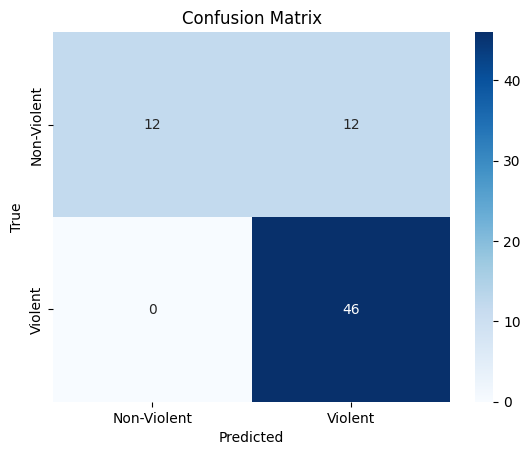

AUC Score: 0.8850


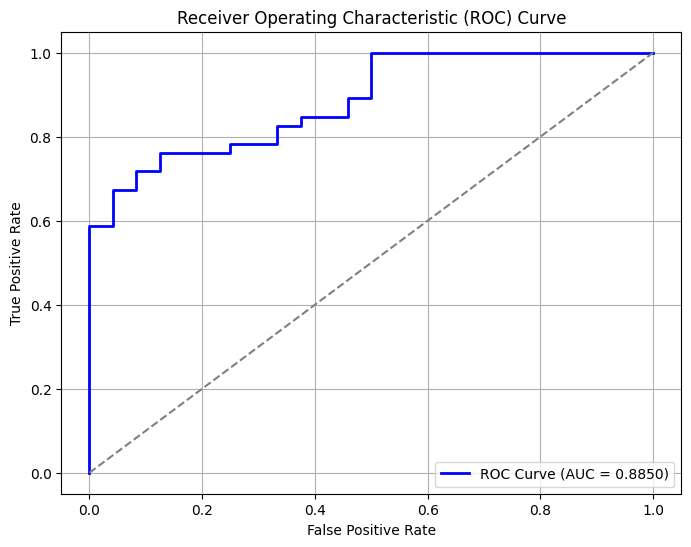

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from tensorflow.keras.models import load_model
from tqdm import tqdm
from sklearn.model_selection import train_test_split

def evaluate_model(model_path, data_dir, sequence_length=8, frame_size=(160, 160), test_split=0.2):
    # Initialize the trainer and load data
    trainer = ViolenceDetectionTrainer(data_dir, sequence_length=sequence_length, frame_size=frame_size)
    videos, labels = trainer.load_video_data()

    # Split the dataset
    X_train_paths, X_test_paths, y_train, y_test = train_test_split(
        videos, labels, test_size=test_split, random_state=42, stratify=labels)

    # Load model
    print("Loading trained model...")
    model = load_model(model_path)

    # Extract frames from test videos
    X_test = []
    y_test_valid = []

    print("Extracting frames from test videos...")
    for path, label in tqdm(zip(X_test_paths, y_test), total=len(X_test_paths)):
        frames = trainer.extract_frames(path)
        if frames is not None:
            X_test.append(frames)
            y_test_valid.append(label)
        else:
            print(f"Failed to extract frames: {path}")

    if not X_test:
        print("No valid test videos found.")
        return

    X_test = np.array(X_test)
    y_test_valid = np.array(y_test_valid)

    # Predict
    print("Running predictions...")
    y_pred_proba = model.predict(X_test).flatten()
    y_pred = (y_pred_proba >= 0.5).astype(int)

    # Evaluate
    acc = accuracy_score(y_test_valid, y_pred)
    print(f"\n✅ Accuracy: {acc:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_test_valid, y_pred, target_names=['Non-Violent', 'Violent']))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_test_valid, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=['Non-Violent', 'Violent'], yticklabels=['Non-Violent', 'Violent'])
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")
    plt.show()

    # AUC
    auc_score = roc_auc_score(y_test_valid, y_pred_proba)
    print(f"AUC Score: {auc_score:.4f}")

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test_valid, y_pred_proba)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
    plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

# Example call:
evaluate_model(model_path='violence_detection_model.h5', data_dir='violence-detection-dataset')


In [2]:
#predictions on a sample video - violence detection

import cv2
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load the trained model
model = load_model('violence_detection_model.h5')

# Parameters
sequence_length = 8
frame_size = (160, 160)

def extract_frames_for_prediction(video_path, sequence_length=8, frame_size=(160, 160)):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    interval = max(total_frames // sequence_length, 1)
    
    frames = []
    count = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if count % interval == 0:
            frame = cv2.resize(frame, frame_size)
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = frame / 255.0
            frames.append(frame)
        count += 1
        if len(frames) == sequence_length:
            break
    cap.release()

    # Pad with black frames if not enough
    while len(frames) < sequence_length:
        frames.append(np.zeros_like(frames[0]))
    
    return np.array(frames)

# Load and preprocess a sample video
video_path = 'subject_tracking_output.avi'
frames = extract_frames_for_prediction(video_path, sequence_length, frame_size)

# Add batch dimension
input_data = np.expand_dims(frames, axis=0)

# Predict
prediction = model.predict(input_data)[0][0]
label = "Violence" if prediction >= 0.5 else "Non-Violence"
confidence = prediction if prediction >= 0.5 else 1 - prediction

print(f"Prediction: {label} ({confidence*100:.2f}% confidence)")


1/1 [==============================] - 1s 1s/step
Prediction: Violence (88.99% confidence)


In [1]:
import cv2
import numpy as np
import tkinter as tk
from PIL import Image, ImageTk
from tensorflow.keras.models import load_model

# Load model
model = load_model('violence_detection_model.h5')

# Parameters
sequence_length = 8
frame_size = (160, 160)
video_path = 'subject_tracking_output.avi'

def extract_frames_for_prediction(video_path):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    interval = max(total_frames // sequence_length, 1)
    
    frames = []
    count = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if count % interval == 0:
            resized = cv2.resize(frame, frame_size)
            rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
            rgb = rgb / 255.0
            frames.append(rgb)
        count += 1
        if len(frames) == sequence_length:
            break
    cap.release()
    
    while len(frames) < sequence_length:
        frames.append(np.zeros_like(frames[0]))
    
    return np.array(frames)

def predict_violence(frames):
    input_data = np.expand_dims(frames, axis=0)
    prediction = model.predict(input_data)[0][0]
    label = "Violence" if prediction >= 0.5 else "Non-Violence"
    confidence = prediction if prediction >= 0.5 else 1 - prediction
    return label, confidence

# Tkinter GUI
root = tk.Tk()
root.title("Violence Detection Viewer")

label_text = tk.StringVar()
label_text.set("Loading prediction...")

label = tk.Label(root, textvariable=label_text, font=('Helvetica', 16), fg="white", bg="black")
label.pack()

canvas = tk.Label(root)
canvas.pack()

cap = cv2.VideoCapture(video_path)

def update_frame():
    ret, frame = cap.read()
    if ret:
        img = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (480, 360))
        img_pil = Image.fromarray(img)
        imgtk = ImageTk.PhotoImage(image=img_pil)
        canvas.imgtk = imgtk
        canvas.configure(image=imgtk)
        root.after(33, update_frame)  # ~30 FPS

# Run prediction once at the start
frames = extract_frames_for_prediction(video_path)
label_result, confidence = predict_violence(frames)
label_text.set(f"{label_result} ({confidence * 100:.2f}% confidence)")

# Start video and GUI
update_frame()
root.mainloop()


1/1 [==============================] - 1s 1s/step
